# Build a Mini-GPT from Scratch (Colab)

An educational, character-level, decoder-only Transformer trained from random initialization on Tiny Shakespeare. No pretrained model and no LLM API.

**Learning objective:** understand tokenization, embeddings, causal self-attention, Transformer blocks, next-token loss, training, and autoregressive generation.

Run the notebook from top to bottom. In Colab, select **Runtime → Change runtime type → T4 GPU** (or another available GPU).

## 0. Runtime and imports

Colab normally includes PyTorch. This notebook uses only PyTorch, Python standard library, and Matplotlib for the loss plot.

In [2]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [3]:
import math, urllib.request, random
from pathlib import Path
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

SEED = 1337
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)
if DEVICE == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


## 1. Download and inspect the training text

We use the Tiny Shakespeare corpus as a compact demonstration dataset. It is not a general-purpose language dataset.

In [4]:
DATA_URL = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
Path('data').mkdir(exist_ok=True)
DATA_PATH = Path('data/tinyshakespeare.txt')
if not DATA_PATH.exists():
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
text = DATA_PATH.read_text(encoding='utf-8')
print('Characters:', len(text))
print(text[:1000])

Characters: 1115394
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in t

## 2. Character-level tokenizer

Each distinct character receives an integer ID. This is intentionally simple: unlike modern GPT tokenizers, it does not split text into subword tokens.

In [5]:
chars = sorted(set(text))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

def encode(s):
    return [stoi[c] for c in s]

def decode(ids):
    return ''.join(itos[int(i)] for i in ids)

all_ids = torch.tensor(encode(text), dtype=torch.long)
split_at = int(0.9 * len(all_ids))
train_data = all_ids[:split_at]
val_data = all_ids[split_at:]
print('Vocabulary size:', vocab_size)
print('Example:', text[:80])
print('Encoded:', encode(text[:20]))
print('Decoded:', decode(encode(text[:20])))

Vocabulary size: 65
Example: First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.
Encoded: [18, 47, 56, 57, 58, 1, 15, 47, 58, 47, 64, 43, 52, 10, 0, 14, 43, 44, 53, 56]
Decoded: First Citizen:
Befor


## 3. Create training batches

For every input sequence `x`, the target `y` is the same sequence shifted one character to the right. The model learns to predict the next character at every position.

In [6]:
BATCH_SIZE = 32
BLOCK_SIZE = 128

def get_batch(split):
    source = train_data if split == 'train' else val_data
    starts = torch.randint(len(source) - BLOCK_SIZE - 1, (BATCH_SIZE,))
    x = torch.stack([source[i:i+BLOCK_SIZE] for i in starts])
    y = torch.stack([source[i+1:i+BLOCK_SIZE+1] for i in starts])
    return x.to(DEVICE), y.to(DEVICE)

xb, yb = get_batch('train')
print('Input batch:', xb.shape)
print('Target batch:', yb.shape)
print('First input:', decode(xb[0][:50].tolist()))
print('First target:', decode(yb[0][:50].tolist()))

Input batch: torch.Size([32, 128])
Target batch: torch.Size([32, 128])
First input:  if die, be brief,
That our swift-winged souls may
First target: if die, be brief,
That our swift-winged souls may 


## 4. Implement one causal self-attention head

Queries ask what a position is looking for; keys describe what each earlier position offers; values carry the information. The lower-triangular mask prevents a position from seeing future characters.

In [7]:
class Head(nn.Module):
    def __init__(self, head_size, n_embd, block_size, dropout):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)
        q = self.query(x)
        # Scaled dot-product attention: QK^T / sqrt(d_k)
        weights = q @ k.transpose(-2, -1) * (k.shape[-1] ** -0.5)
        # Causal mask: hide current/future positions to the right
        weights = weights.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        weights = F.softmax(weights, dim=-1)
        weights = self.dropout(weights)
        return weights @ self.value(x)

# Shape check
head = Head(head_size=16, n_embd=64, block_size=BLOCK_SIZE, dropout=0.1).to(DEVICE)
print('Attention head output:', head(torch.randn(2, 20, 64, device=DEVICE)).shape)

Attention head output: torch.Size([2, 20, 16])


## 5. Multi-head attention and feed-forward network

Multiple heads learn different attention patterns in parallel. The feed-forward network then applies a small nonlinear transformation independently at each sequence position.

In [8]:
class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size, n_embd, block_size, dropout):
        super().__init__()
        self.heads = nn.ModuleList([
            Head(head_size, n_embd, block_size, dropout) for _ in range(num_heads)
        ])
        self.proj = nn.Linear(num_heads * head_size, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        joined = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(joined))

class FeedForward(nn.Module):
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )
    def forward(self, x):
        return self.net(x)

print('Multi-head and feed-forward modules defined.')

Multi-head and feed-forward modules defined.


## 6. Transformer block

Each block uses pre-layer normalization, residual connections, masked self-attention, and a feed-forward network.

In [9]:
class Block(nn.Module):
    def __init__(self, n_embd, num_heads, block_size, dropout):
        super().__init__()
        head_size = n_embd // num_heads
        self.sa = MultiHeadAttention(num_heads, head_size, n_embd, block_size, dropout)
        self.ffwd = FeedForward(n_embd, dropout)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

## 7. Assemble the GPT language model

Token embeddings encode character identity. Positional embeddings encode sequence order. The final linear layer produces one logit per vocabulary character.

In [10]:
class GPTLanguageModel(nn.Module):
    def __init__(self, vocab_size, block_size, n_embd=128, num_heads=4,
                 num_layers=3, dropout=0.1):
        super().__init__()
        assert n_embd % num_heads == 0
        self.block_size = block_size
        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[
            Block(n_embd, num_heads, block_size, dropout)
            for _ in range(num_layers)
        ])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok = self.token_embedding(idx)
        pos_ids = torch.arange(T, device=idx.device)
        pos = self.position_embedding(pos_ids)
        x = self.blocks(tok + pos)
        logits = self.lm_head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(B*T, -1), targets.reshape(B*T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-4)
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, next_id), dim=1)
        return idx

# Initial model configuration: small enough for a Colab GPU
N_EMBD = 128
N_HEADS = 4
N_LAYERS = 3
DROPOUT = 0.1
model = GPTLanguageModel(vocab_size, BLOCK_SIZE, N_EMBD, N_HEADS, N_LAYERS, DROPOUT).to(DEVICE)
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')
logits, loss = model(xb, yb)
print('Logits shape:', logits.shape)
print('Initial loss:', round(loss.item(), 4))

Parameters: 627,009
Logits shape: torch.Size([32, 128, 65])
Initial loss: 4.1946


## 8. Train the model

The objective is cross-entropy next-character prediction. A lower validation loss generally indicates that the model is getting better at predicting held-out text. The default run is 1,500 steps; start with 100–200 steps to confirm everything works.

In [11]:
MAX_STEPS = 1500       # change to 150 for a quick smoke test
LEARNING_RATE = 3e-4
EVAL_INTERVAL = 250
EVAL_ITERS = 20

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

@torch.no_grad()
def estimate_loss():
    model.eval()
    out = {}
    for split in ('train', 'val'):
        losses = torch.zeros(EVAL_ITERS)
        for k in range(EVAL_ITERS):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

history = {'step': [], 'train': [], 'val': []}
model.train()
for step in range(MAX_STEPS + 1):
    if step % EVAL_INTERVAL == 0 or step == MAX_STEPS:
        metrics = estimate_loss()
        history['step'].append(step)
        history['train'].append(metrics['train'])
        history['val'].append(metrics['val'])
        print(f"step {step:4d} | train {metrics['train']:.3f} | val {metrics['val']:.3f}")
    if step == MAX_STEPS:
        break
    X, Y = get_batch('train')
    _, loss = model(X, Y)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()

step    0 | train 4.191 | val 4.193
step  250 | train 2.433 | val 2.440
step  500 | train 2.217 | val 2.233
step  750 | train 1.981 | val 2.048
step 1000 | train 1.838 | val 1.948
step 1250 | train 1.743 | val 1.886
step 1500 | train 1.673 | val 1.852


## 9. Plot the learning curve

A successful first run should generally show training loss decreasing. Validation loss can fluctuate; compare its trend rather than expecting every evaluation point to improve.

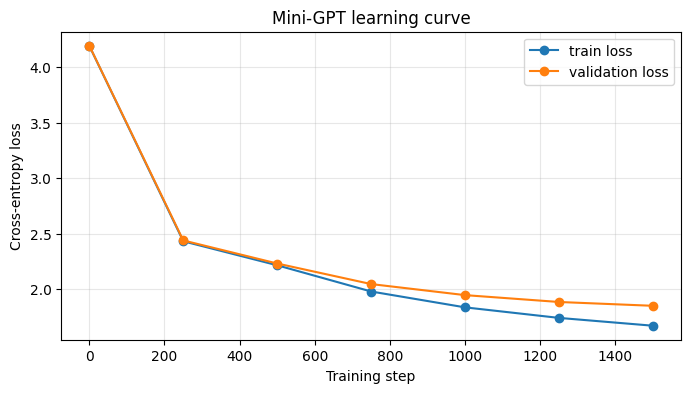

In [12]:
plt.figure(figsize=(8, 4))
plt.plot(history['step'], history['train'], marker='o', label='train loss')
plt.plot(history['step'], history['val'], marker='o', label='validation loss')
plt.xlabel('Training step')
plt.ylabel('Cross-entropy loss')
plt.title('Mini-GPT learning curve')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 10. Generate text

Generation is autoregressive: predict one character, append it to the context, and repeat. Temperature controls sampling randomness. Lower values are more conservative; higher values are more varied.

In [13]:
@torch.no_grad()
def generate_from_prompt(prompt='', max_new_tokens=500, temperature=0.8):
    model.eval()
    if prompt:
        # Ignore unknown prompt characters rather than crashing
        prompt_ids = [stoi[c] for c in prompt if c in stoi]
        if not prompt_ids:
            prompt_ids = [0]
    else:
        prompt_ids = [0]
    context = torch.tensor([prompt_ids], dtype=torch.long, device=DEVICE)
    output = model.generate(context, max_new_tokens, temperature)
    return decode(output[0].tolist())

print(generate_from_prompt('ROMEO:', max_new_tokens=500, temperature=0.8))

ROMEO:
My shore, taw in thou must of heOf that here propeses
To made in eJulie of the but callow,
Are the trief to mine will thou should me,
When take may many a have speak of turn beal My to her;
The bidly no the ansure is ansure the trices
The to and prost this all hourd.

AUTOLWISS:
Ya love heave I rease to weout.


BESTER, CARLIO:
When it her it of have I leave Edwer to her with,
As strand the seat that than am ribe the hearms of our the
hand nour hold more; oll the deat, the murn bid my lifly
Mas


## 11. Save the checkpoint

The checkpoint contains model weights, vocabulary, and architecture settings so the model can be reconstructed later.

In [14]:
Path('outputs').mkdir(exist_ok=True)
checkpoint = {
    'model_state_dict': model.state_dict(),
    'chars': chars,
    'config': {
        'block_size': BLOCK_SIZE,
        'n_embd': N_EMBD,
        'num_heads': N_HEADS,
        'num_layers': N_LAYERS,
        'dropout': DROPOUT,
    },
}
torch.save(checkpoint, 'outputs/mini_gpt.pt')
Path('outputs/generated_sample.txt').write_text(
    generate_from_prompt('ROMEO:', max_new_tokens=500), encoding='utf-8'
)
print('Saved outputs/mini_gpt.pt and outputs/generated_sample.txt')

Saved outputs/mini_gpt.pt and outputs/generated_sample.txt




```
# This is formatted as code
```

## 12. What We have built — and what to try next

You implemented a decoder-only Transformer with:

- character-to-integer tokenization;
- token and positional embeddings;
- scaled dot-product causal self-attention;
- multi-head attention;
- feed-forward layers;
- residual connections and layer normalization;
- cross-entropy next-character training;
- autoregressive sampling.

**Experiments:** change `N_HEADS`, `N_LAYERS`, `N_EMBD`, `BLOCK_SIZE`, `MAX_STEPS`, or `temperature` and compare the loss curve and generated samples. Keep `N_EMBD` divisible by `N_HEADS`.

**Limitations:** this is an educational toy model, not ChatGPT. It learns character patterns from one small corpus and does not have modern GPT's subword tokenizer, scale, instruction tuning, or factual reliability.

In [18]:
prompt = input("Enter your prompt: ")

context = torch.tensor(
    encode(prompt),
    dtype=torch.long,
    device=DEVICE
).unsqueeze(0)

generated = model.generate(
    context,
    max_new_tokens=300,
    temperature=0.8
)

print("\nGenerated text:\n")
print(decode(generated[0].tolist()))

Enter your prompt: KING:

Generated text:

KING:
My seer's to me, strue of experticy
To head in of that aus rewect him beforth a parese
To from the life ching like here;
The do he the micking haid my ladings 'thy son.

CLADY VINCENTIO:
Ell strans Ant do rething of our so a your of your eVstor
To are your in to otherebut I meen be dies:
But of Eam
